# Pierwsza sieć w Keras: klasyfikacja obrazów (Fashion MNIST)

**Plan notatnika:**
1. Zbiór danych Fashion MNIST
2. Przygotowanie danych
3. Model bazowy i budowa sieci
4. Kompilacja i trening
5. Ocena modelu
6. Gdzie model się myli: macierz pomyłek
7. Predykcje na nowych danych
8. Przeuczenie i regularyzacja (Dropout)
9. Podsumowanie

**Cele:**
- przejść pełny cykl pracy z siecią w Keras: dane, model, kompilacja, trening, ocena, predykcja,
- sprawdzić, czy sieć jest lepsza od modelu bazowego,
- policzyć liczbę parametrów sieci i sprawdzić ją względem `model.summary()`,
- zobaczyć przeuczenie i sprawdzić, jak pomaga Dropout.

## 1. Zbiór danych Fashion MNIST

Fashion-MNIST to popularny zbiór do nauki klasyfikacji obrazów, będący trudniejszym zamiennikiem klasycznego MNIST (odręczne cyfry). Składa się z 70 000 obrazów w skali szarości o rozmiarze 28x28 pikseli (60 000 treningowych i 10 000 testowych), podzielonych na 10 klas ubrań i obuwia:

| Etykieta | Opis |
|---|---|
| 0 | T-shirt/top |
| 1 | Trouser (spodnie) |
| 2 | Pullover (sweter) |
| 3 | Dress (sukienka) |
| 4 | Coat (płaszcz) |
| 5 | Sandal (sandał) |
| 6 | Shirt (koszula) |
| 7 | Sneaker (but sportowy) |
| 8 | Bag (torba) |
| 9 | Ankle boot (botek) |

Zmienną docelową jest **numer klasy** (0-9), a cechami - 784 wartości pikseli (28x28).

## 2. Przygotowanie danych

Dane pobieramy bezpośrednio z Keras (przy pierwszym uruchomieniu zostaną pobrane z internetu i zapamiętane lokalnie). Następnie:
- **skalujemy piksele** z zakresu 0-255 do 0-1 (sieci uczą się stabilniej na małych wartościach, por. standaryzacja w notatniku 01),
- wydzielamy **zbiór walidacyjny** (5000 obrazów) ze zbioru treningowego, ze stratyfikacją (po tyle samo obrazów z każdej klasy). Zbiór walidacyjny służy do monitorowania treningu, a zbiór testowy zostaje nietknięty do końcowej oceny (rozdział 4.4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


TensorFlow: 2.21.0


In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()

X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, test_size=5000, random_state=SEED, stratify=y_train_full
)

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print('X_train:', X_train.shape, ' X_valid:', X_valid.shape, ' X_test:', X_test.shape)
print('Zakres wartości pikseli:', X_train.min(), '-', X_train.max())

X_train: (55000, 28, 28)  X_valid: (5000, 28, 28)  X_test: (10000, 28, 28)
Zakres wartości pikseli: 0.0 - 1.0


Zobaczmy po jednym przykładzie z każdej klasy.

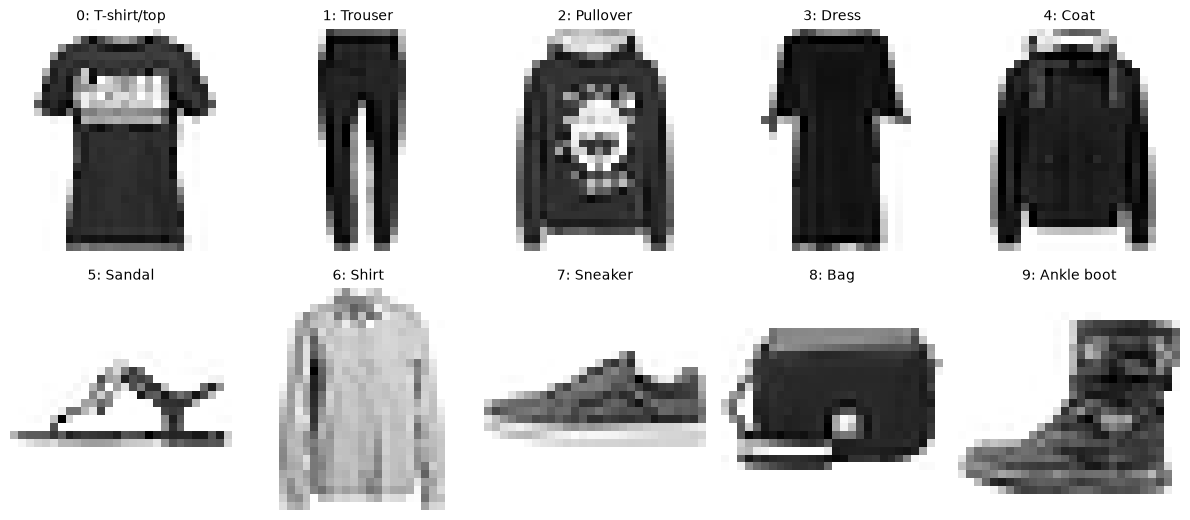

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for k, ax in enumerate(axes.ravel()):
    first = np.where(y_train == k)[0][0]
    ax.imshow(X_train[first], cmap='binary')
    ax.set_title(f'{k}: {class_names[k]}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Model bazowy i budowa sieci

**Model bazowy.** Klasy w Fashion MNIST są zrównoważone, więc model, który zgaduje klasę, ma dokładność około 10%. Taka jest „poprzeczka”, którą sieć musi przeskoczyć.

In [4]:
print('Udział klas w zbiorze testowym:')
print((np.bincount(y_test) / len(y_test)).round(2))
print('Dokładność modelu bazowego (zawsze ta sama klasa):', np.bincount(y_test).max() / len(y_test))

Udział klas w zbiorze testowym:
[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
Dokładność modelu bazowego (zawsze ta sama klasa): 0.1


**Sieć.** Użyjemy `keras.Sequential`, czyli stosu warstw układanych po kolei:
1. **Flatten** - „spłaszcza” każdy obraz 28x28 do wektora o długości 784 (bez parametrów do uczenia),
2. **Dense (128 neuronów, ReLU)** - warstwa ukryta,
3. **Dense (10 neuronów, softmax)** - warstwa wyjściowa: po jednym neuronie na klasę, a softmax zamienia wyniki na prawdopodobieństwa (notatnik 02).

In [5]:
model = keras.models.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax'),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Sprawdźmy liczbę parametrów ze wzoru z notatnika 01, $(n_{in}+1)\cdot n_{out}$:
- warstwa ukryta: $(784+1)\cdot128 = 100\,480$,
- warstwa wyjściowa: $(128+1)\cdot10 = 1290$.

In [6]:
hidden = (784 + 1) * 128
output = (128 + 1) * 10
print('Ze wzoru:', hidden, '+', output, '=', hidden + output)
print('Keras:   ', model.count_params())

Ze wzoru: 100480 + 1290 = 101770
Keras:    101770


## 4. Kompilacja i trening

### Kompilacja
Przed treningiem określamy (zgodnie z tabelą z notatnika 02):
- **funkcję straty** - `sparse_categorical_crossentropy`: klasyfikacja wieloklasowa, a etykiety to pojedyncze liczby 0-9,
- **optymalizator** - `adam` (notatnik 03),
- **metrykę** - `accuracy`.

In [7]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

### Trening
Metoda `fit()` uczy model. Przekazujemy dane treningowe, liczbę epok i dane walidacyjne. Dodatkowo używamy `EarlyStopping`: jeśli strata walidacyjna nie poprawia się przez 3 kolejne epoki, trening jest przerywany, a model wraca do wag z najlepszej epoki (`restore_best_weights=True`). Rozmiar paczki to domyślnie 32 obserwacje.

In [8]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=15,
    validation_data=(X_valid, y_valid),
    callbacks=[early_stopping],
    verbose=2,
)

Epoch 1/15
1719/1719 - 1s - 682us/step - accuracy: 0.8209 - loss: 0.5095 - val_accuracy: 0.8726 - val_loss: 0.3635
Epoch 2/15
1719/1719 - 1s - 493us/step - accuracy: 0.8627 - loss: 0.3821 - val_accuracy: 0.8824 - val_loss: 0.3294
Epoch 3/15
1719/1719 - 1s - 494us/step - accuracy: 0.8756 - loss: 0.3408 - val_accuracy: 0.8842 - val_loss: 0.3153
Epoch 4/15
1719/1719 - 1s - 489us/step - accuracy: 0.8844 - loss: 0.3146 - val_accuracy: 0.8926 - val_loss: 0.3027
Epoch 5/15
1719/1719 - 1s - 493us/step - accuracy: 0.8920 - loss: 0.2946 - val_accuracy: 0.8934 - val_loss: 0.2993
Epoch 6/15
1719/1719 - 1s - 489us/step - accuracy: 0.8976 - loss: 0.2772 - val_accuracy: 0.8934 - val_loss: 0.2959
Epoch 7/15
1719/1719 - 1s - 491us/step - accuracy: 0.9025 - loss: 0.2642 - val_accuracy: 0.8958 - val_loss: 0.2933
Epoch 8/15
1719/1719 - 1s - 486us/step - accuracy: 0.9070 - loss: 0.2528 - val_accuracy: 0.8942 - val_loss: 0.2936
Epoch 9/15
1719/1719 - 1s - 482us/step - accuracy: 0.9102 - loss: 0.2427 - val_a

Liczba iteracji w epoce to $55\,000 / 32 \approx 1719$ (tyle pokazuje `fit()` przy każdej epoce), czyli wagi są aktualizowane 1719 razy w każdej epoce (notatnik 03: mini-batch).

## 5. Ocena modelu

Zwizualizujmy historię treningu.

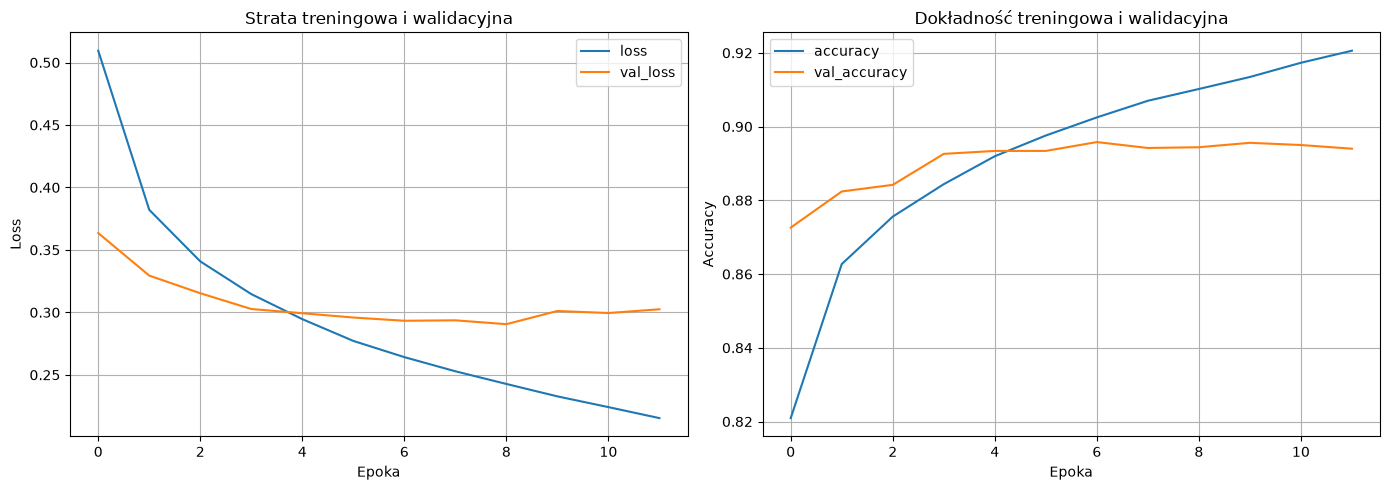

Liczba wykonanych epok: 12
Najlepsza epoka (numeracja od 1): 9


In [9]:
history_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

history_df[['loss', 'val_loss']].plot(ax=axes[0])
axes[0].set_title('Strata treningowa i walidacyjna')
axes[0].set_xlabel('Epoka')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

history_df[['accuracy', 'val_accuracy']].plot(ax=axes[1])
axes[1].set_title('Dokładność treningowa i walidacyjna')
axes[1].set_xlabel('Epoka')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print('Liczba wykonanych epok:', len(history_df))
print('Najlepsza epoka (numeracja od 1):', history_df['val_loss'].idxmin() + 1)

### Jak interpretować te wykresy
- **Dobrze:** `loss` i `val_loss` maleją, a `accuracy` i `val_accuracy` rosną.
- **Przeuczenie:** `loss` treningowa dalej maleje, ale `val_loss` przestaje maleć i zaczyna rosnąć; `accuracy` treningowa rośnie, a walidacyjna stoi w miejscu.
- **Niedouczenie:** obie dokładności są niskie i prawie się nie poprawiają.

Ostateczną ocenę wykonujemy na **zbiorze testowym**, którego model nie widział ani w uczeniu, ani przy wyborze liczby epok.

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Dokładność na zbiorze testowym: {test_acc:.4f}   (model bazowy: 0.1000)')
print(f'Dokładność na zbiorze walidacyjnym (najlepsza epoka): {history_df["val_accuracy"].iloc[history_df["val_loss"].idxmin()]:.4f}')

Test loss: 0.3329
Dokładność na zbiorze testowym: 0.8834   (model bazowy: 0.1000)
Dokładność na zbiorze walidacyjnym (najlepsza epoka): 0.8944


Sieć jest wielokrotnie lepsza od modelu bazowego. Wynik testowy jest nieco niższy od walidacyjnego (około 1 punkt procentowy), co jest normalne: epokę wybraliśmy na podstawie zbioru walidacyjnego. Model dobrze generalizuje.

## 6. Gdzie model się myli: macierz pomyłek

Sama dokładność nie mówi, **które klasy** są mylone. Użyjmy macierzy pomyłek (rozdział 3.2) i raportu klasyfikacji.

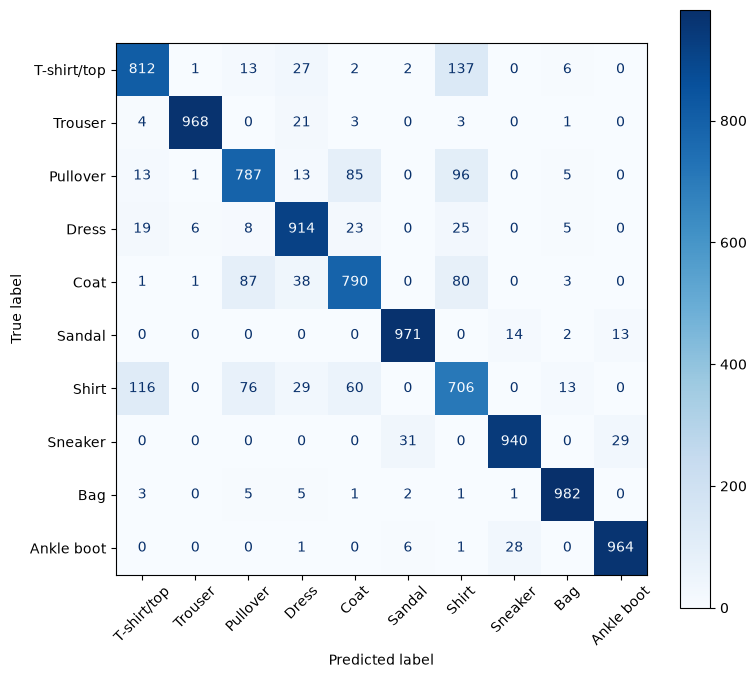

In [11]:
y_proba_test = model.predict(X_test, verbose=0)
y_pred_test = np.argmax(y_proba_test, axis=1)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, display_labels=class_names, xticks_rotation=45, cmap='Blues', ax=ax
)
plt.tight_layout()
plt.show()

In [12]:
cm = confusion_matrix(y_test, y_pred_test)
errors = [(class_names[i], class_names[j], cm[i, j])
          for i in range(10) for j in range(10) if i != j]
errors = pd.DataFrame(errors, columns=['prawdziwa klasa', 'przewidziana klasa', 'liczba pomyłek'])
print('Najczęstsze pomyłki:')
print(errors.sort_values('liczba pomyłek', ascending=False).head(5).to_string(index=False))

print()
print(classification_report(y_test, y_pred_test, target_names=class_names, digits=3))

Najczęstsze pomyłki:
prawdziwa klasa przewidziana klasa  liczba pomyłek
    T-shirt/top              Shirt             137
          Shirt        T-shirt/top             116
       Pullover              Shirt              96
           Coat           Pullover              87
       Pullover               Coat              85

              precision    recall  f1-score   support

 T-shirt/top      0.839     0.812     0.825      1000
     Trouser      0.991     0.968     0.979      1000
    Pullover      0.806     0.787     0.797      1000
       Dress      0.872     0.914     0.893      1000
        Coat      0.820     0.790     0.804      1000
      Sandal      0.959     0.971     0.965      1000
       Shirt      0.673     0.706     0.689      1000
     Sneaker      0.956     0.940     0.948      1000
         Bag      0.966     0.982     0.974      1000
  Ankle boot      0.958     0.964     0.961      1000

    accuracy                          0.883     10000
   macro avg      0.88

Najwięcej pomyłek dotyczy podobnych do siebie rodzajów odzieży (koszula, T-shirt, sweter, płaszcz), a najlepiej rozpoznawane są klasy wyraźnie różne od reszty, np. spodnie, torby i obuwie. Sieć w obecnej postaci patrzy na piksele jako na zwykłe cechy i nie wykorzystuje faktu, że sąsiednie piksele są powiązane - do tego służą sieci konwolucyjne (CNN), które wykraczają poza ten kurs.

## 7. Predykcje na nowych danych

Model zwraca dla każdego obrazu 10 prawdopodobieństw (softmax). Klasę wybieramy jako ta z największym prawdopodobieństwem (`argmax`). Zobaczmy kilka pierwszych obrazów testowych.

Przewidziane klasy: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt']
Rzeczywiste klasy:  ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt']
Suma prawdopodobieństw dla pierwszego obrazu: 1.0


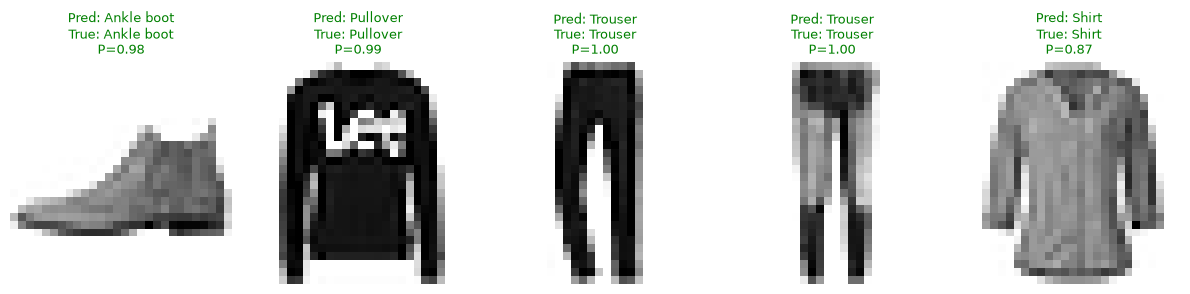

In [13]:
X_new = X_test[:5]
y_true_new = y_test[:5]
y_proba = model.predict(X_new, verbose=0)
y_pred = np.argmax(y_proba, axis=1)
confidence = np.max(y_proba, axis=1)

print('Przewidziane klasy:', np.array(class_names)[y_pred].tolist())
print('Rzeczywiste klasy: ', np.array(class_names)[y_true_new].tolist())
print('Suma prawdopodobieństw dla pierwszego obrazu:', y_proba[0].sum().round(3))

plt.figure(figsize=(12, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_new[i], cmap='binary')
    color = 'green' if y_pred[i] == y_true_new[i] else 'red'
    plt.title(f'Pred: {class_names[y_pred[i]]}\nTrue: {class_names[y_true_new[i]]}\nP={confidence[i]:.2f}',
              color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## 8. Przeuczenie i regularyzacja (Dropout)

Sieci mają dużo parametrów i łatwo „uczą się na pamięć” zbioru treningowego (rozdział 4.3). Sprawdźmy to na **większej** sieci (256 i 128 neuronów) trenowanej przez 15 epok **bez** `EarlyStopping`, a potem porównajmy ją z taką samą siecią z warstwami **Dropout**.

**Dropout** to technika regularyzacji: w każdej iteracji treningu losowo „wyłącza” podaną część neuronów (tu 30%), co zmusza sieć do uczenia się cech, które nie zależą od pojedynczych neuronów. Podczas predykcji wszystkie neurony są włączone.

In [14]:
def build_model(dropout_rate):
    layers = [
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Flatten(),
        keras.layers.Dense(256, activation='relu'),
    ]
    if dropout_rate > 0:
        layers.append(keras.layers.Dropout(dropout_rate))
    layers.append(keras.layers.Dense(128, activation='relu'))
    if dropout_rate > 0:
        layers.append(keras.layers.Dropout(dropout_rate))
    layers.append(keras.layers.Dense(10, activation='softmax'))

    m = keras.models.Sequential(layers)
    m.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return m

histories = {}
for name, rate in [('bez Dropout', 0.0), ('Dropout 0.3', 0.3)]:
    keras.utils.set_random_seed(SEED)
    m = build_model(rate)
    h = m.fit(X_train, y_train, epochs=15, batch_size=128,
              validation_data=(X_valid, y_valid), verbose=0)
    histories[name] = pd.DataFrame(h.history)
    print(f'{name:12s} parametrów: {m.count_params()},  '
          f'accuracy treningowe: {h.history["accuracy"][-1]:.3f},  walidacyjne: {h.history["val_accuracy"][-1]:.3f}')

bez Dropout  parametrów: 235146,  accuracy treningowe: 0.933,  walidacyjne: 0.901
Dropout 0.3  parametrów: 235146,  accuracy treningowe: 0.896,  walidacyjne: 0.901


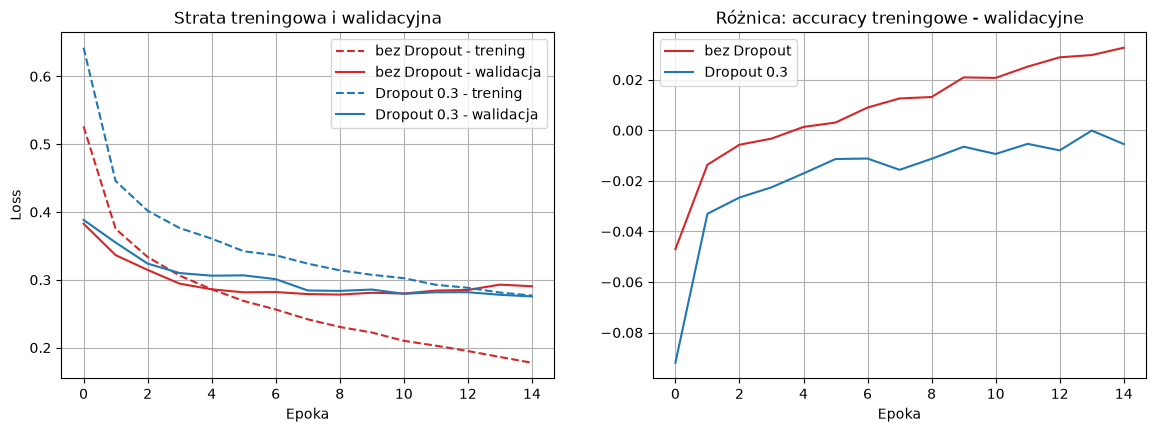

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, color in [('bez Dropout', 'tab:red'), ('Dropout 0.3', 'tab:blue')]:
    axes[0].plot(histories[name]['loss'], '--', color=color, label=f'{name} - trening')
    axes[0].plot(histories[name]['val_loss'], '-', color=color, label=f'{name} - walidacja')
    gap = histories[name]['accuracy'] - histories[name]['val_accuracy']
    axes[1].plot(gap, color=color, label=name)
axes[0].set_title('Strata treningowa i walidacyjna')
axes[0].set_xlabel('Epoka')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)
axes[1].set_title('Różnica: accuracy treningowe - walidacyjne')
axes[1].set_xlabel('Epoka')
axes[1].legend()
axes[1].grid(True)
plt.show()

Obserwacje:
- **bez Dropout** strata treningowa stale maleje, a strata walidacyjna wypłaszcza się i pod koniec lekko rośnie. Różnica między accuracy treningowym i walidacyjnym stale się powiększa - to początek przeuczenia (sieć zapamiętuje zbiór treningowy),
- **z Dropout** krzywe treningowa i walidacyjna pozostają blisko siebie, różnica accuracy jest bliska zera, a strata walidacyjna na końcu jest nieco niższa,
- accuracy walidacyjne w obu wariantach jest niemal takie samo, więc Dropout nie zawsze poprawia wynik. Jego rola to ograniczenie przeuczenia, co pozwala trenować dłużej i większe sieci bez utraty jakości.

Obie techniki walki z przeuczeniem (`EarlyStopping` i Dropout) można łączyć.

## 9. Podsumowanie

1. Pełny cykl w Keras: dane (skalowanie, podział na train/valid/test) -> `Sequential` -> `compile` -> `fit` -> `evaluate` -> `predict`.
2. Zawsze porównujemy sieć z **modelem bazowym** (tu 10% dla 10 równych klas).
3. Liczbę parametrów warstwy gęstej liczymy ze wzoru $(n_{in}+1)\cdot n_{out}$; `model.summary()` i `model.count_params()` to potwierdzają.
4. `EarlyStopping` zatrzymuje trening, gdy strata walidacyjna przestaje maleć, i przywraca najlepsze wagi.
5. **Macierz pomyłek** pokazuje, które klasy są mylone (tu: podobne rodzaje odzieży).
6. **Dropout** to prosta regularyzacja ograniczająca przeuczenie.
7. Do obrazów w praktyce stosuje się sieci konwolucyjne (CNN), które uwzględniają sąsiedztwo pikseli.